# §3. Model Evaluation

In [10]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import torch


DATAPATH = Path("../data")
MODELPATH = Path("../models")
TEST_DATA = "processed_test.csv"


def read_data(filename, datapath=DATAPATH):
    file_path = datapath / filename
    if file_path.is_file():
        return pd.read_csv(file_path)
    else:
        raise FileNotFoundError(f"{file_path} does not exist.")

In [44]:
from sklearn.metrics import f1_score, accuracy_score, log_loss
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder


import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
from transformers import BertTokenizer, BertModel

class TriageModel(nn.Module):
    """Triage model combining text, numeric, and categorical features for classification."""
    def __init__(self, text_model, num_features, cat_cardinalities, n_classes):
        """Initialize the TriageModel.

        Args:
            text_model: Pretrained text model (e.g., BERT).
            num_features: Number of numeric features.
            cat_cardinalities: List of cardinalities for categorical features.
            n_classes: Number of output classes.
        """
        super().__init__()
        self.text_model = text_model
        hidden = text_model.config.hidden_size  # e.g., 768

        # categorical embeddings
        self.cat_embs = nn.ModuleList([
            nn.Embedding(cardinality, min(32, (cardinality + 1) // 2))
            for cardinality in cat_cardinalities
        ])
        cat_out = sum(emb.embedding_dim for emb in self.cat_embs)

        # numeric branch
        self.num_net = nn.Sequential(
            nn.LayerNorm(num_features),
            nn.Linear(num_features, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
        )

        fusion_in = hidden + 32 + cat_out
        self.head = nn.Sequential(
            nn.Linear(fusion_in, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, n_classes),
        )

    def forward(self, input_ids, attention_mask, x_num, x_cat):
        text_out = self.text_model(input_ids=input_ids, attention_mask=attention_mask)
        text_vec = text_out.last_hidden_state[:, 0, :]   # CLS

        cat_vecs = [emb(x_cat[:, i]) for i, emb in enumerate(self.cat_embs)]
        cat_vec = torch.cat(cat_vecs, dim=1) if cat_vecs else None

        num_vec = self.num_net(x_num)

        if cat_vec is not None:
            fused = torch.cat([text_vec, num_vec, cat_vec], dim=1)
        else:
            fused = torch.cat([text_vec, num_vec], dim=1)

        return self.head(fused)


from typing import List
from transformers import PreTrainedTokenizer

class TriageDataset(Dataset):
    """Custom Dataset for Triage classification """
    def __init__(
            self,
            X_num: np.ndarray,
            X_cat: np.ndarray,
            X_text: np.ndarray,
            tokenizer: PreTrainedTokenizer,
            y: np.ndarray=None,
            max_length: int = 32
        ):
        """
        Initialize the TriageDataset
        
        Args:
            X_num (np.ndarray): Array with numerical features
            X_cat (np.ndarray): Array with categorical features
            X_text (np.ndarray): Array with text features
            y (np.ndarray): Target labels
            tokenizer (PreTrainedTokenizer): Tokenizer for text data
            max_length (int, optional): Maximum token length for text. Defaults to 32.
        """
        self.x_num = X_num.astype(np.float32)
        self.x_cat = X_cat.astype(np.int64)
        self.texts = X_text.tolist()
        self.y = None if y is None else np.asarray(y, dtype=np.int64)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):        
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt",
        )
        item = {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "x_num": torch.tensor(self.x_num[idx], dtype=torch.float32),
            "x_cat": torch.tensor(self.x_cat[idx], dtype=torch.long),
        }
        if self.y is not None:
            item["y"] = torch.tensor(self.y[idx], dtype=torch.long)
        return item

def run_eval(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_y, all_pred = [], []

    with torch.no_grad():
        for batch in loader:
            y = batch["y"].to(device)
            x_num = batch["x_num"].to(device)
            x_cat = batch["x_cat"].to(device)
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)

            logits = model(input_ids, attention_mask, x_num, x_cat)
            loss = criterion(logits, y)

            total_loss += loss.item() * y.size(0)
            preds = torch.argmax(logits, dim=1)

            all_y.append(y.cpu().numpy())
            all_pred.append(preds.cpu().numpy())

    y_true = np.concatenate(all_y)
    y_pred = np.concatenate(all_pred)

    out = {
        "loss": total_loss / len(loader.dataset),
        "acc": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
    }
    return out

LABEL = 'triage_acuity'

physiological_variables = ['age', 'weight_kg', 'height_cm']
vital_signs_variables = ['systolic_bp', 'diastolic_bp', 'heart_rate', 'respiratory_rate', 'temperature_c', 'spo2']
other_variables = ['num_active_medications', 'num_comorbidities',  'gcs_total', 'pain_score', 'news2_score']
concurrency_variables = ['num_prior_ed_visits_12m', 'num_prior_admissions_12m']
categorical_variables = ['sex', 'arrival_mode', 'mental_status_triage', 'pain_location', 'chief_complaint_system', 'transport_origin']
hx_variables = ['hx_hypertension', 'hx_diabetes_type2',
       'hx_diabetes_type1', 'hx_asthma', 'hx_copd', 'hx_heart_failure',
       'hx_atrial_fibrillation', 'hx_ckd', 'hx_liver_disease', 'hx_malignancy',
       'hx_obesity', 'hx_depression', 'hx_anxiety', 'hx_dementia',
       'hx_epilepsy', 'hx_hypothyroidism', 'hx_hyperthyroidism', 'hx_hiv',
       'hx_coagulopathy', 'hx_immunosuppressed', 'hx_pregnant',
       'hx_substance_use_disorder', 'hx_coronary_artery_disease',
       'hx_stroke_prior', 'hx_peripheral_vascular_disease'] 
text_variables = ['chief_complaint_raw']

def prepare_data(df, preprocessor, tokenizer, label_encoder=None, label_col="triage_acuity"):
    cat_features = categorical_variables
    num_features = (
        physiological_variables + vital_signs_variables + other_variables
        + concurrency_variables + hx_variables
    )
    text_col = text_variables[0]
    features = num_features + cat_features + [text_col]

    X = df[features]
    X_text = X[text_col].fillna("").astype(str).reset_index(drop=True)
    X_tab = preprocessor.transform(X)

    n_num = len(num_features)
    n_cat = len(cat_features)
    x_num = X_tab[:, :n_num].astype(np.float32)
    x_cat = (X_tab[:, n_num:n_num + n_cat].astype(np.int64) + 1)

    y_enc = None
    if label_col in df.columns:
        if label_encoder is None:
            raise ValueError("label_encoder is required when labels are present")
        y_enc = label_encoder.transform(df[label_col])

    ds = TriageDataset(X_num=x_num, X_cat=x_cat, X_text=X_text.values, y=y_enc, tokenizer=tokenizer)
    return DataLoader(ds, batch_size=32, shuffle=False)

def predict_torch(model, loader, device):
    model.to(device)
    model.eval()
    all_preds, all_probs = [], []
    with torch.no_grad():
        for batch in loader:
            logits = model(
                batch["input_ids"].to(device),
                batch["attention_mask"].to(device),
                batch["x_num"].to(device),
                batch["x_cat"].to(device),
            )
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(probs, dim=1)
            all_probs.append(probs.cpu().numpy())
            all_preds.append(preds.cpu().numpy())
    return np.concatenate(all_preds), np.concatenate(all_probs)


In [6]:
# Load baseline
baseline_model = joblib.load(MODELPATH / "baseline_model.pkl")

In [8]:
# Load triage model (Bio_ClinicalBERT)

tokenizer = BertTokenizer.from_pretrained("emilyalsentzer/Bio_ClinicalBERT")
text_model = BertModel.from_pretrained("emilyalsentzer/Bio_ClinicalBERT")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

loaded_weights = torch.load(MODELPATH / "triage_model.pth", map_location=device)
triageModel = TriageModel(text_model, **loaded_weights["model_hyperparams"])
triageModel.load_state_dict(loaded_weights["model_state_dict"])

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 16540.50it/s]
[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


<All keys matched successfully>

In [13]:
data = read_data(TEST_DATA)
data.head()

,patient_id,site_id,triage_nurse_id,age,weight_kg,height_cm,systolic_bp,diastolic_bp,heart_rate,respiratory_rate,...,hx_hypothyroidism,hx_hyperthyroidism,hx_hiv,hx_coagulopathy,hx_immunosuppressed,hx_pregnant,hx_substance_use_disorder,hx_coronary_artery_disease,hx_stroke_prior,hx_peripheral_vascular_disease
0,TG-FZUFCRZS3,SITE-TMP-01,NURSE-0050,24,86.9,177.2,73.0,77.9,75.3,26.7,...,0,0,1,0,1,0,0,0,0,0
1,TG-SSCOXTYI1,SITE-TMP-01,NURSE-0001,53,67.0,156.2,112.1,70.0,92.7,20.6,...,0,0,1,0,0,0,0,0,1,0
2,TG-JY74ZR35D,SITE-HEL-01,NURSE-0018,88,76.3,149.4,131.2,70.8,91.1,27.7,...,0,0,0,0,0,0,0,0,1,0
3,TG-JDKD5G62X,SITE-TUR-01,NURSE-0028,59,103.8,172.4,136.9,78.2,78.3,14.9,...,0,1,0,0,0,0,0,0,0,0
4,TG-J1BSAAXR0,SITE-TMP-01,NURSE-0033,44,76.7,168.5,NaN,NaN,65.5,15.2,...,0,0,1,0,0,1,1,0,0,0


In [19]:
X = data.copy()

In [20]:
y_pred_baseline = baseline_model.predict(X)

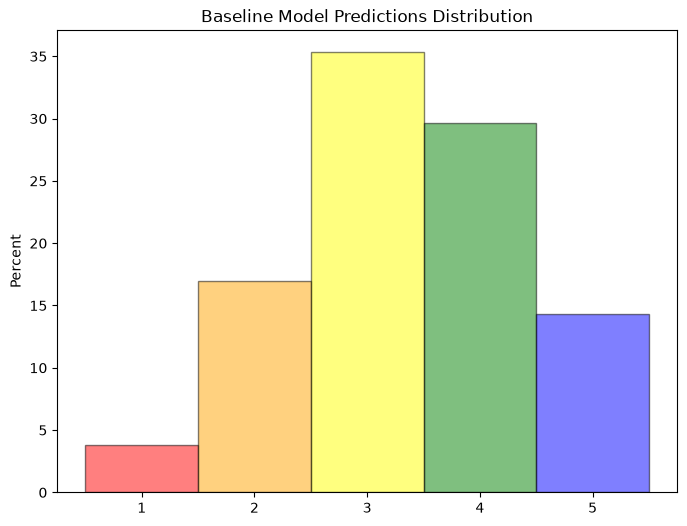

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

esi_colors = {1: 'red', 2: 'orange', 3: 'yellow', 4: 'green', 5: 'blue'}

fig, ax = plt.subplots(1,1, figsize=(8,6))
hp = sns.histplot(y_pred_baseline, ax=ax, stat='percent', discrete=True)
for p in hp.patches:
    p.set_facecolor(esi_colors[int(p.get_x()+1)])
    p.set_edgecolor('black')
    p.set_alpha(0.5)
ax.set_title("Baseline Model Predictions Distribution")
plt.show()


In [31]:
data.columns

Index(['patient_id', 'site_id', 'triage_nurse_id', 'age', 'weight_kg',
       'height_cm', 'systolic_bp', 'diastolic_bp', 'heart_rate',
       'respiratory_rate', 'temperature_c', 'spo2', 'num_active_medications',
       'num_comorbidities', 'gcs_total', 'pain_score', 'news2_score',
       'num_prior_ed_visits_12m', 'num_prior_admissions_12m', 'sex',
       'arrival_mode', 'mental_status_triage', 'pain_location',
       'chief_complaint_system', 'transport_origin', 'chief_complaint_raw',
       'hx_hypertension', 'hx_diabetes_type2', 'hx_diabetes_type1',
       'hx_asthma', 'hx_copd', 'hx_heart_failure', 'hx_atrial_fibrillation',
       'hx_ckd', 'hx_liver_disease', 'hx_malignancy', 'hx_obesity',
       'hx_depression', 'hx_anxiety', 'hx_dementia', 'hx_epilepsy',
       'hx_hypothyroidism', 'hx_hyperthyroidism', 'hx_hiv', 'hx_coagulopathy',
       'hx_immunosuppressed', 'hx_pregnant', 'hx_substance_use_disorder',
       'hx_coronary_artery_disease', 'hx_stroke_prior',
       'hx_periph

In [41]:
# Let's examine some critial patient predictions from the baseline model

esi_level = 1
esi_patients = (y_pred_baseline == esi_level)

esi_data = data[esi_patients][['patient_id', 'age', 'sex', 'chief_complaint_raw', 'pain_score', 'news2_score', 'gcs_total', 'arrival_mode']]
esi_data = esi_data.sort_values('news2_score', ascending=False)
esi_data.head()

,patient_id,age,sex,chief_complaint_raw,pain_score,news2_score,gcs_total,arrival_mode
74,TG-KTLY9SHTH,25,M,massive lower GI haemorrhage in known patient,9,17,6,ambulance
230,TG-IX3TBKZT9,59,F,"severe cardiogenic shock, no prior history of ...",10,17,4,ambulance
19316,TG-E4LQOH60P,46,M,severe traumatic brain injury with vomiting,9,17,9,transfer
10811,TG-YIP9RIGEU,54,F,found unconscious mechanism unclear,10,17,4,walk-in
11386,TG-GOWPQ7VEL,78,M,blunt thoracic trauma with haemothorax,7,17,6,walk-in


In [ ]:
preprocessor = joblib.load(MODELPATH / "preprocessor.joblib")
label_encoder = joblib.load(MODELPATH / "label_encoder.joblib")

# dataloader = prepare_data(data, preprocessor, tokenizer, label_encoder, label_col=LABEL)
